# Does changing the coach win more points? The notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/john-bruene/pointzerofive-data/blob/main/does-firing-the-coach-work/story_001_coach_firing.ipynb)

This R notebook recomputes every statistic in
[Does changing the coach win more points?](https://pointzerofive.net/2026/09/does-firing-the-coach-work),
story #001 on *pointzerofive*, from the raw match files. Colab opens it with the R runtime; run it
top to bottom (`Runtime → Run all`). The bootstrap cell runs 18 × 10,000 replicates and takes
about a minute.

**The question:** when a Bundesliga club changes coach mid-season, does the team get better,
or would it have recovered anyway?

Each quoted number is printed and checked with `stopifnot()` against the published dataset
`data/does-firing-the-coach-work.json`. Requires base R and `jsonlite` (preinstalled in Colab).
The pipeline that wrote the dataset is `notebooks/coach_firing_pipeline.R`; its console output,
with R and package versions, is `data/does-firing-the-coach-work.output.txt`.

In [1]:
library(jsonlite)

BASE <- "https://raw.githubusercontent.com/john-bruene/pointzerofive-data/main/does-firing-the-coach-work/"
REPO <- ".."

# A file of this story: next to the notebook (pointzerofive-data), in the website's repository,
# else downloaded from pointzerofive-data.
fetch_path <- function(rel) {
  for (local in c(basename(rel), file.path(REPO, rel))) if (file.exists(local)) return(local)
  paste0(BASE, basename(rel))
}

near <- function(a, b, tol = 0.0015) stopifnot(abs(a - b) <= tol)

read_csv_utf8 <- function(path) {
  read.csv(path, encoding = "UTF-8", stringsAsFactors = FALSE, check.names = FALSE)
}

RAW <- fetch_path("notebooks/raw/bundesliga/coach_games_L1.csv")
games <- read_csv_utf8(RAW)
matches <- read_csv_utf8(fetch_path("notebooks/raw/bundesliga/matches.csv"))
pub <- fromJSON(fetch_path("data/does-firing-the-coach-work.json"), simplifyVector = FALSE)
cat(sprintf("%d Bundesliga matches with managers, seasons %d–%d\n",
            nrow(games), min(games$season), max(games$season)))
head(games)

4284 Bundesliga matches with managers, seasons 2012–2025


,season,round,date,home_club_name,away_club_name,home_club_goals,away_club_goals,home_club_manager_name,away_club_manager_name
,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,2012,1. Matchday,2012-08-24,Borussia Dortmund,SV Werder Bremen,2,1,Jürgen Klopp,Thomas Schaaf
2,2012,1. Matchday,2012-08-25,Borussia Mönchengladbach,TSG 1899 Hoffenheim,2,1,Lucien Favre,Markus Babbel
3,2012,1. Matchday,2012-08-25,Eintracht Frankfurt,Bayer 04 Leverkusen,2,1,Armin Veh,Sascha Lewandowski
4,2012,1. Matchday,2012-08-25,FC Augsburg,Fortuna Düsseldorf,0,2,Markus Weinzierl,Norbert Meier
5,2012,1. Matchday,2012-08-25,Hamburger SV,1.FC Nuremberg,0,1,Thorsten Fink,Dieter Hecking
6,2012,1. Matchday,2012-08-25,SC Freiburg,1.FSV Mainz 05,1,1,Christian Streich,Thomas Tuchel


## 1. Two sources, one set of results

`coach_games_L1.csv` comes from the transfermarkt-datasets `games` table (CC0 1.0, data from
Transfermarkt.de). `matches.csv` is parsed from openfootball (CC0 1.0) by
`notebooks/bundesliga_matches_pipeline.R`. Team names differ between the two, so we compare, for
each match date, the list of scorelines.

In [2]:
by_date <- function(df, h, a) {
  lines <- paste(df[[h]], df[[a]], sep = "-")
  tapply(lines, df$date, function(x) paste(sort(x, method = "radix"), collapse = " "))
}
tm <- by_date(games, "home_club_goals", "away_club_goals")
of <- by_date(matches[matches$date %in% names(tm), ], "home_goals", "away_goals")
stopifnot(setequal(names(tm), names(of)), all(tm == of[names(tm)]))
cat(sprintf("all %d match dates agree\n", length(tm)))

all 1364 match dates agree


## 2. Finding coach changes

One row per team per game, in date order within each season. A **coach change** is the first
game under a different manager. If the previous manager comes back later in the same season,
it was a stand-in (suspension, illness) and does not count. A caretaker followed by a new
permanent coach counts as one change. The column `adj` (points above an expectation from the
opponent's strength) is used only by the "opponents = yes" paths.

In [3]:
K <- 6L

# Points above expectation given the opponent (spec §7.1, opponents=yes).
#
# Expected points come from a league-wide linear fit of points on the opponent's season points
# per game (this match excluded) and home advantage. The opponent's season figure includes games
# played after a coach change: leakage of later information, accepted and disclosed.
add_expected_points <- function(tg) {
  key <- paste(tg$season, tg$club)
  sums <- tapply(tg$pts, key, sum)
  sizes <- tapply(tg$pts, key, length)
  okey <- paste(tg$season, tg$opp)
  opp_pts_here <- c(3, 1, 0)[match(tg$pts, c(0, 1, 3))]
  tg$opp_ppg_loo <- (sums[okey] - opp_pts_here) / (sizes[okey] - 1)
  x <- cbind(1, tg$opp_ppg_loo, tg$home)
  beta <- qr.coef(qr(x), tg$pts)
  tg$adj <- tg$pts - drop(x %*% beta)
  tg
}

# One row per team per game, in date order within each season.
team_games <- function() {
  l1 <- read_csv_utf8(RAW)
  home <- data.frame(season = l1$season, date = l1$date, home = 1L, club = l1$home_club_name,
                     opp = l1$away_club_name, gf = l1$home_club_goals,
                     ga = l1$away_club_goals, mgr = l1$home_club_manager_name)
  away <- data.frame(season = l1$season, date = l1$date, home = 0L, club = l1$away_club_name,
                     opp = l1$home_club_name, gf = l1$away_club_goals,
                     ga = l1$home_club_goals, mgr = l1$away_club_manager_name)
  tg <- rbind(home, away)
  tg <- tg[order(tg$season, tg$club, tg$date, method = "radix"), ]
  rownames(tg) <- NULL
  tg$pts <- ifelse(tg$gf > tg$ga, 3L, ifelse(tg$gf == tg$ga, 1L, 0L))
  key <- paste(tg$season, tg$club)
  tg$n <- ave(seq_along(key), key, FUN = seq_along)
  season_ppg <- tapply(tg$pts, key, mean)
  tg$opp_ppg <- unname(season_ppg[paste(tg$season, tg$opp)])
  add_expected_points(tg)
}

find_changes <- function(tg, k) {
  changes <- list()
  standins <- 0L
  key <- paste(tg$season, tg$club, sep = "\r")
  for (grp in unique(key)) {
    d <- tg[key == grp, ]
    m <- d$mgr
    n <- length(m)
    i <- 1L  # 0-based position of the game being looked at, as in the original Python
    while (i < n) {
      if (m[i + 1] == m[i]) {
        i <- i + 1L
        next
      }
      outgoing <- m[i]
      rest <- m[(i + 1):n]
      if (outgoing %in% rest) {
        # Stand-in: skip to the outgoing manager's return
        standins <- standins + 1L
        i <- i + match(outgoing, rest)
        next
      }
      permanent <- m[min(i + k - 1L, n - 1L) + 1L]
      changes[[length(changes) + 1]] <- data.frame(
        season = d$season[1], club = d$club[1], game = i + 1L,
        out = outgoing, `in` = m[i + 1], permanent = permanent, check.names = FALSE
      )
      i <- i + k  # a caretaker-then-permanent sequence is one change
    }
  }
  list(changes = do.call(rbind, changes), standins = standins)
}

tg <- team_games()
cat(sprintf("league average: %.3f points per game\n", mean(tg$pts)))
near(round(mean(tg$pts), 3), pub$summary$leaguePpg)
fc <- find_changes(tg, K)
changes <- fc$changes
cat(sprintf("%d coach changes, %d stand-ins excluded\n", nrow(changes), fc$standins))
stopifnot(nrow(changes) == pub$summary$changes, fc$standins == pub$summary$standins)
head(changes)

league average: 1.377 points per game


116 coach changes, 10 stand-ins excluded


,season,club,game,out,in,permanent
,<int>,<chr>,<int>,<chr>,<chr>,<chr>
1,2012,1.FC Nuremberg,18,Dieter Hecking,Michael Wiesinger,Michael Wiesinger
2,2012,FC Schalke 04,18,Huub Stevens,Jens Keller,Jens Keller
3,2012,SV Werder Bremen,34,Thomas Schaaf,Wolfgang Rolff,Wolfgang Rolff
4,2012,SpVgg Greuther Fürth,23,Mike Büskens,Ludwig Preis,Frank Kramer
5,2012,TSG 1899 Hoffenheim,16,Markus Babbel,Frank Kramer,Marco Kurz
6,2012,TSG 1899 Hoffenheim,28,Marco Kurz,Markus Gisdol,Markus Gisdol


## 3. Six games before, six games after

For every team-game we sum points over the previous six games (`pre`) and over the next six
including the current one (`post`). Changes in the first or last six games of a season have
an incomplete window and drop out. Control stretches have no coach change in the twelve games
around them.

In [4]:
# Sum of the k values before position i (NA without k of them).
roll_prev <- function(x, k) {
  n <- length(x)
  out <- rep(NA_real_, n)
  if (n > k) for (i in (k + 1):n) out[i] <- sum(x[(i - k):(i - 1)])
  out
}

# Sum of the value at i and the k - 1 after it (NA without k of them).
roll_next <- function(x, k) {
  n <- length(x)
  out <- rep(NA_real_, n)
  if (n >= k) for (i in 1:(n - k + 1)) out[i] <- sum(x[i:(i + k - 1)])
  out
}

windows <- function(tg, k) {
  key <- paste(tg$season, tg$club)
  by_team <- function(x, f) ave(as.numeric(x), key, FUN = function(v) f(v, k))
  tg$pre <- by_team(tg$pts, roll_prev)
  tg$post <- by_team(tg$pts, roll_next)
  tg$pre_adj <- by_team(tg$adj, roll_prev)
  tg$post_adj <- by_team(tg$adj, roll_next)
  tg$opp_post <- by_team(tg$opp_ppg, roll_next) / k
  tg
}

split_windows <- function(tg, changes, k) {
  w <- windows(tg, k)
  wkey <- paste(w$season, w$club, w$n)
  idx <- match(paste(changes$season, changes$club, changes$game), wkey)
  treated <- cbind(changes, w[idx, setdiff(names(w), c("season", "club"))])
  treated <- treated[!is.na(treated$pre) & !is.na(treated$post), ]
  rownames(treated) <- NULL
  pool <- w[!is.na(w$pre) & !is.na(w$post), ]
  # a stretch is clean if no change falls on games n - k + 1 .. n + k of the same club-season
  near <- unlist(lapply(seq_len(nrow(changes)), function(r) {
    paste(changes$season[r], changes$club[r], (changes$game[r] - k):(changes$game[r] + k - 1))
  }))
  control <- pool[!(paste(pool$season, pool$club, pool$n) %in% near), ]
  rownames(control) <- NULL
  list(treated = treated, control = control)
}

sp <- split_windows(tg, changes, K)
treated <- sp$treated
control <- sp$control
E <- pub$effect
cat(sprintf("%d changes with full windows; %d control stretches\n", nrow(treated), nrow(control)))
cat(sprintf("before %.3f, after %.3f points per game\n", mean(treated$pre) / K, mean(treated$post) / K))
cat(sprintf("improved: %.1f%%\n", 100 * mean(treated$post > treated$pre)))
stopifnot(nrow(treated) == pub$summary$analysed, nrow(control) == pub$summary$controlPositions)
near(mean(treated$pre) / K, E$prePpg); near(mean(treated$post) / K, E$postPpg)
near(mean(treated$post > treated$pre), E$improvedShare)

91 changes with full windows; 4779 control stretches


before 0.679, after 1.282 points per game


improved: 80.2%


## 4. Regression to the mean, without any coach change

Take every six-game stretch where the coach stayed. How many points per game followed, by
how many points the team had just taken? If form simply continued, the circles would sit on the
diagonal.

stretches with <= 4 points: 1.181 points per game next (n = 554)


0 points from 6: 0.930; 18 points from 6: 2.226


77% of changes came after 5 points or fewer


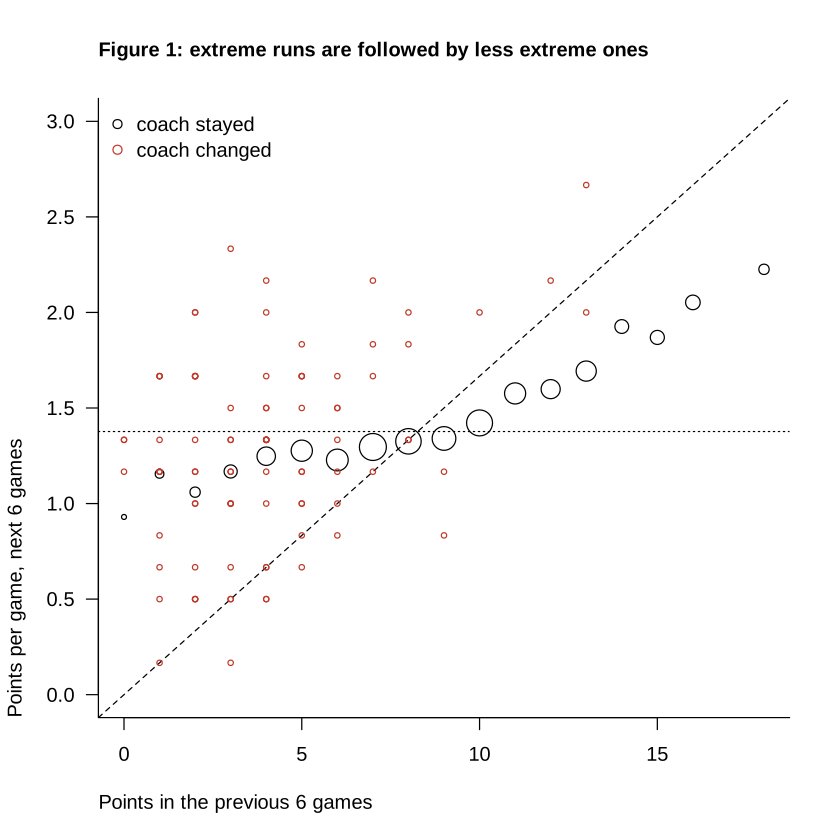

In [5]:
depth_mean <- tapply(control$post, control$pre, mean)
depth_n <- tapply(control$post, control$pre, length)
depth_pre <- as.integer(names(depth_mean))
plot(depth_pre, depth_mean / K, cex = sqrt(depth_n / max(depth_n)) * 3, xlim = c(0, 18),
     ylim = c(0, 3), bty = "l", las = 1, xlab = "Points in the previous 6 games",
     ylab = "Points per game, next 6 games",
     main = "Figure 1: extreme runs are followed by less extreme ones", adj = 0, cex.main = 1)
abline(0, 1 / 6, lty = 2)
abline(h = mean(tg$pts), lty = 3)
points(treated$pre, treated$post / K, col = "#c0392b", cex = 0.6)
legend("topleft", c("coach stayed", "coach changed"), pch = 1, col = c("black", "#c0392b"),
       bty = "n")

slump <- control[control$pre <= 4, ]
cat(sprintf("stretches with <= 4 points: %.3f points per game next (n = %d)\n",
            mean(slump$post) / K, nrow(slump)))
cat(sprintf("0 points from 6: %.3f; 18 points from 6: %.3f\n",
            depth_mean[["0"]] / K, depth_mean[["18"]] / K))
near(mean(slump$post) / K, pub$slump$postPpg)
for (row in pub$depth) near(depth_mean[[as.character(row$pre)]] / K, row$postPpg)
cat(sprintf("%.0f%% of changes came after 5 points or fewer\n", 100 * mean(treated$pre <= 5)))

## 5. The fair comparison

For each change, take all control stretches with **exactly the same points in the previous six
games** and average their next six. The effect of a change is its own next-six points minus
that average, divided by six (points per game).

In [6]:
# Mean of post minus the matched controls' mean post, per game.
effect <- function(treated, control, k) {
  cm <- tapply(control$post, control$pre, mean)
  cp <- cm[as.character(treated$pre)]
  ok <- !is.na(cp)
  mean(treated$post[ok] - cp[ok]) / k
}

cm <- tapply(control$post, control$pre, mean)
ctrl_post <- cm[as.character(treated$pre)]
eff <- effect(treated, control, K)
cat(sprintf("matched controls: %.3f points per game after\n", mean(ctrl_post) / K))
cat(sprintf("effect: %+.3f points per game (%+.2f over six games)\n", eff, eff * K))
ctrl_improved <- mean(tapply(control$post > control$pre, control$pre, mean)[as.character(treated$pre)])
cat(sprintf("matched controls that improved: %.1f%%\n", 100 * ctrl_improved))
near(mean(ctrl_post) / K, E$controlPostPpg); near(eff, E$perGame)
near(ctrl_improved, E$controlImprovedShare)
cat(sprintf("opponents after: %.3f (changes) vs %.3f (controls)\n",
            mean(treated$opp_post), mean(control$opp_post)))
near(mean(treated$opp_post), E$oppPostPpg); near(mean(control$opp_post), E$controlOppPostPpg)

matched controls: 1.209 points per game after


effect: +0.073 points per game (+0.44 over six games)


matched controls that improved: 75.9%


opponents after: 1.374 (changes) vs 1.377 (controls)


### How uncertain is that?

Cluster bootstrap: resample the changes, and resample the control stretches by club-season
(stretches from the same club-season overlap, so they are not independent). 10,000 replicates
per calculation path. The 95% confidence interval runs from the 250th to the 9,751st replicate;
the p-value counts the replicates on the far side of zero. With these two definitions, p < 0.05
holds exactly when the interval excludes zero. Path i (1 to 18, in fork order) uses
`set.seed(4 * 1000 + i)`, so the numbers below match the published ones exactly. The next cell is
`notebooks/coach_firing_stats.R`.

In [7]:
# coach_firing_stats.R
# ──────────────────────────────────────────────────────────────────────
# Estimators and the cluster bootstrap for story #001 (relaunch spec §7.1). The pipeline and the
# notebook use the same procedure and the same seeds, so they produce identical numbers.
#
# All three comparisons share one formula. For treated rows i with outcome y_i and match bin b_i,
# and control groups g with outcome sums S[g, b] and counts C[g, b]:
#
#     effect = mean over i of ( y_i - S[., b_i] / C[., b_i] ) / k
#
# over the treated rows whose bin has at least one control. A bootstrap draw resamples treated
# rows and control groups (club-seasons) with replacement and is stored as count weights.
#
#   matched:    y = post-window points, b = pre-window points, S/C = control post by pre
#   before:     y = post - pre, one bin, S = 0 and C = 1 (no comparison group)
#   all_slumps: y = post - pre, one bin, S/C = control (post - pre) over slump windows
#
# Requires: base R only. Bins are 1-based here (bin = points before + 1).
# ──────────────────────────────────────────────────────────────────────

ALPHA <- 0.05

# A design: k, y (n_t), bins (n_t, 1-based), s and c (n_g x n_bins).
design <- function(k, y, bins, s, c) list(k = k, y = y, bins = bins, s = s, c = c)

# Effect in points per game for treated weights u (b x n_t) and group weights w (b x n_g).
effects <- function(d, u, w) {
  cp <- (w %*% d$s) / (w %*% d$c)
  cpi <- cp[, d$bins, drop = FALSE]
  valid <- is.finite(cpi)
  diff <- matrix(d$y, nrow(cpi), ncol(cpi), byrow = TRUE) - cpi
  diff[!valid] <- 0
  rowSums(u * diff) / rowSums(u * valid) / d$k
}

point_estimate <- function(d) {
  effects(d, matrix(1, 1, length(d$y)), matrix(1, 1, nrow(d$s)))
}

# Per replicate: resample treated rows, then control groups.
draw_weights <- function(n_t, n_g, b) {
  u <- matrix(0, b, n_t)
  w <- matrix(0, b, n_g)
  for (r in seq_len(b)) {
    u[r, ] <- tabulate(sample.int(n_t, n_t, replace = TRUE), n_t)
    w[r, ] <- tabulate(sample.int(n_g, n_g, replace = TRUE), n_g)
  }
  list(u = u, w = w)
}

# Replicates from the current random stream (set.seed() before the call).
bootstrap <- function(d, b, chunk = 1000) {
  reps <- unlist(lapply(seq(1, b, by = chunk), function(start) {
    dw <- draw_weights(length(d$y), nrow(d$s), min(chunk, b - start + 1))
    effects(d, dw$u, dw$w)
  }))
  if (anyNA(reps)) stop("a replicate had no comparison case at all")
  reps
}

# Treated mean, comparison mean and their difference (points per game) for the same weights
# as effects(); the difference is effects() itself. For the result table (estimation_table.R).
parts <- function(d, u, w) {
  cp <- (w %*% d$s) / (w %*% d$c)
  cpi <- cp[, d$bins, drop = FALSE]
  valid <- is.finite(cpi)
  cpi[!valid] <- 0
  nu <- rowSums(u * valid)
  treated <- rowSums(u * valid * matrix(d$y, nrow(cpi), ncol(cpi), byrow = TRUE)) / nu / d$k
  comparison <- rowSums(u * cpi) / nu / d$k
  cbind(treated = treated, comparison = comparison, effect = effects(d, u, w))
}

# parts() per replicate, from the current random stream; same draws as bootstrap().
bootstrap_parts <- function(d, b, chunk = 1000) {
  do.call(rbind, lapply(seq(1, b, by = chunk), function(start) {
    dw <- draw_weights(length(d$y), nrow(d$s), min(chunk, b - start + 1))
    parts(d, dw$u, dw$w)
  }))
}

# 95% range from order statistics and the matching two-sided bootstrap p-value.
# With m = alpha/2 * B, the range is the m-th to the (B + 1 - m)-th smallest replicate and
# p = 2 * min(#{<= 0}, #{>= 0}) / B. Then p < alpha exactly when the range excludes 0.
summarize <- function(reps, alpha = ALPHA) {
  b <- length(reps)
  m <- round(alpha / 2 * b)
  stopifnot("alpha/2 * B must be a whole number" = abs(alpha / 2 * b - m) < 1e-9)
  s <- sort(reps)
  lo <- s[m]
  hi <- s[b + 1 - m]
  p <- min(1, 2 * min(sum(reps <= 0), sum(reps >= 0)) / b)
  stopifnot((p < alpha) == (lo > 0 || hi < 0))
  list(ci_low = lo, ci_high = hi, p = p)
}

# Matrix (n_g x n_bins) of sums of v by group g and bin.
sum_by <- function(n_g, n_bins, g, bin, v) {
  out <- matrix(0, n_g, n_bins)
  if (length(v)) {
    sums <- rowsum(v, g + (bin - 1) * n_g)
    out[as.integer(rownames(sums))] <- sums
  }
  out
}

# All comparison x opponents designs for one window length k, named "comparison|opponents".
build_designs <- function(treated, control, k) {
  key <- paste(control$season, control$club, sep = "\r")
  groups <- unique(key[order(control$season, control$club, method = "radix")])
  gidx <- match(key, groups)
  n_g <- length(groups)
  cpre <- as.integer(control$pre)
  slump <- cpre <= (2 * k) %/% 3
  # all_slumps compares changes made in a slump with all slump windows; changes after a
  # better run would otherwise face controls that rebound more by chance alone.
  t_slump <- as.integer(treated$pre) <= (2 * k) %/% 3
  ones <- rep(1L, nrow(treated))
  out <- list()
  cols <- list(no = c("pre", "post"), yes = c("pre_adj", "post_adj"))
  for (opponents in names(cols)) {
    pre_col <- cols[[opponents]][1]
    post_col <- cols[[opponents]][2]
    t_post <- as.numeric(treated[[post_col]])
    t_diff <- t_post - as.numeric(treated[[pre_col]])
    c_post <- as.numeric(control[[post_col]])
    c_diff <- c_post - as.numeric(control[[pre_col]])

    s <- sum_by(n_g, 3 * k + 1, gidx, cpre + 1, c_post)
    c <- sum_by(n_g, 3 * k + 1, gidx, cpre + 1, rep(1, length(c_post)))
    out[[paste("matched", opponents, sep = "|")]] <-
      design(k, t_post, as.integer(treated$pre) + 1L, s, c)

    out[[paste("before", opponents, sep = "|")]] <-
      design(k, t_diff, ones, matrix(0, n_g, 1), matrix(1, n_g, 1))

    s1 <- sum_by(n_g, 1, gidx[slump], rep(1, sum(slump)), c_diff[slump])
    c1 <- sum_by(n_g, 1, gidx[slump], rep(1, sum(slump)), rep(1, sum(slump)))
    out[[paste("all_slumps", opponents, sep = "|")]] <-
      design(k, t_diff[t_slump], ones[t_slump], s1, c1)
  }
  out
}

last game before the change: 0.154 points on average


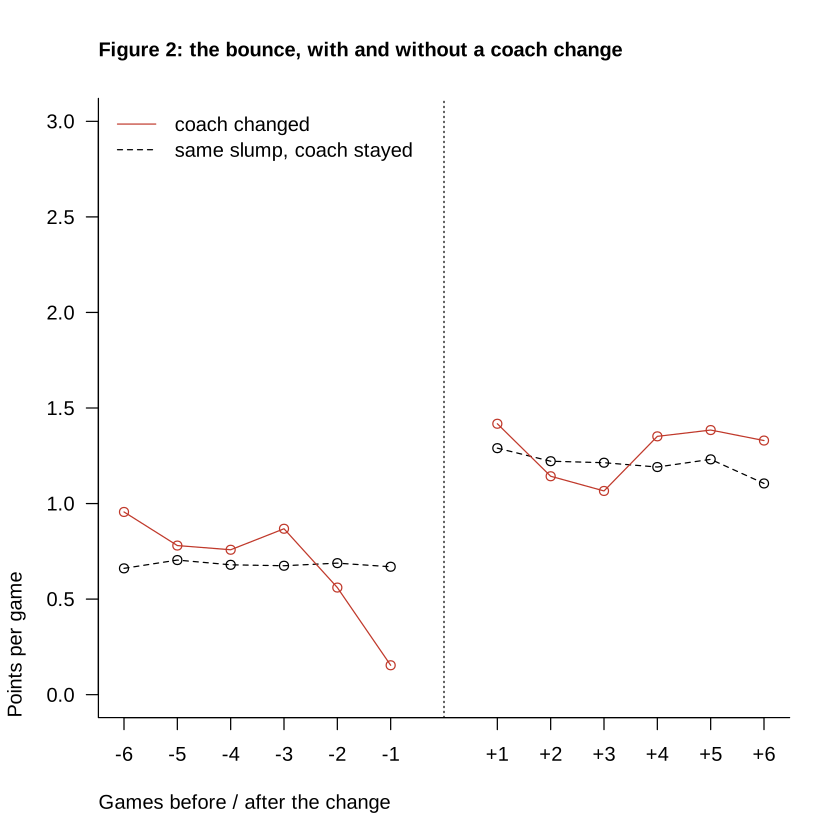

In [8]:
# Points per game at relative games -k..-1 and +1..+k, controls matched on pre.
trajectories <- function(tg, treated, control, k) {
  pkey <- paste(tg$season, tg$club, tg$n)
  vec <- function(df) {
    sapply(-k:(k - 1), function(j) tg$pts[match(paste(df$season, df$club, df$n + j), pkey)])
  }
  t <- vec(treated)
  cv <- vec(control)
  by_pre <- rowsum(cv, control$pre) / as.vector(table(control$pre))
  c <- by_pre[as.character(treated$pre), , drop = FALSE]
  list(t = t, c = c)
}

traj <- trajectories(tg, treated, control, K)
t_traj <- colMeans(traj$t, na.rm = TRUE)
c_traj <- colMeans(traj$c, na.rm = TRUE)
for (i in seq_along(t_traj)) near(t_traj[i], pub$trajectory$changes[[i]])
for (i in seq_along(c_traj)) near(c_traj[i], pub$trajectory$controls[[i]])
cat(sprintf("last game before the change: %.3f points on average\n", t_traj[K]))

rel <- c(-K:-1, 1:K)
x <- c(1:K, (K + 2):(2 * K + 1))
plot(x, t_traj, type = "n", ylim = c(0, 3), bty = "l", las = 1, xaxt = "n",
     xlab = "Games before / after the change", ylab = "Points per game",
     main = "Figure 2: the bounce, with and without a coach change", adj = 0, cex.main = 1)
axis(1, at = x, labels = sprintf("%+d", rel))
abline(v = K + 1, lty = 3)
for (h in list(1:K, (K + 1):(2 * K))) {
  lines(x[h], c_traj[h], type = "o", lty = 2)
  lines(x[h], t_traj[h], type = "o", col = "#c0392b")
}
legend("topleft", c("coach changed", "same slump, coach stayed"), lty = c(1, 2),
       col = c("#c0392b", "black"), bty = "n")

## 6. Every calculation path

Three choices decide the answer: what to compare with, how many games to look at, and whether
the opponents' strength counts. 3 × 3 × 2 = 18 paths. Each is recomputed here and must equal
the published table.

In [9]:
B <- 10000L      # bootstrap replicates per calculation path (spec §7.1)
SEED <- 4L       # path i (1..18, fork order) uses set.seed(SEED * 1000 + i)
FORK_OPTIONS <- list(
  comparison = c("before", "matched", "all_slumps"),
  window = c("5", "6", "10"),
  opponents = c("no", "yes")
)

# Every combination of the forks in the claim file, in fork order (spec §7.1).
compute_specs <- function(tg, forks) {
  ids <- vapply(forks, function(f) f$id, "")
  options <- lapply(forks, function(f) vapply(f$options, function(o) o$id, ""))
  names(options) <- ids
  stopifnot(identical(ids, names(FORK_OPTIONS)), identical(options, FORK_OPTIONS))
  designs <- list()
  for (window in FORK_OPTIONS$window) {
    k <- as.integer(window)
    ch <- find_changes(tg, k)$changes
    sp <- split_windows(tg, ch, k)
    designs[[window]] <- build_designs(sp$treated, sp$control, k)
  }
  specs <- list()
  for (comparison in FORK_OPTIONS$comparison) {
    for (window in FORK_OPTIONS$window) {
      for (opponents in FORK_OPTIONS$opponents) {
        i <- length(specs) + 1L
        choices <- list(comparison = comparison, window = window, opponents = opponents)
        key <- paste0(names(choices), "=", unlist(choices), collapse = "|")
        d <- designs[[window]][[paste(comparison, opponents, sep = "|")]]
        set.seed(SEED * 1000L + i)
        s <- summarize(bootstrap(d, B))
        specs[[i]] <- c(list(choices = choices, effect = point_estimate(d)), s,
                        list(n = length(d$y)))
        cat(sprintf("  %s: n=%d, %+.3f [%+.3f, %+.3f] p=%.4f\n", key, length(d$y),
                    specs[[i]]$effect, s$ci_low, s$ci_high, s$p))
      }
    }
  }
  specs
}

specs <- compute_specs(tg, pub$forks)
for (i in seq_along(specs)) {
  r <- specs[[i]]
  p <- pub$specs[[i]]
  stopifnot(identical(r$choices, p$choices), r$n == p$n)
  for (k in c("effect", "ci_low", "ci_high", "p")) stopifnot(abs(r[[k]] - p[[k]]) < 1e-9)
}
yes <- sum(vapply(specs, function(s) s$p < ALPHA && s$effect > 0, TRUE))
cat(sprintf("the answer is yes on %d of %d paths\n", yes, length(specs)))

crisis <- treated[treated$pre <= 4, ]
cat(sprintf("crisis changes: %.3f → %.3f points per game\n",
            mean(crisis$pre) / K, mean(crisis$post) / K))
near(mean(crisis$pre) / K, pub$slump$crisisPrePpg); near(mean(crisis$post) / K, pub$slump$crisisPostPpg)

  comparison=before|window=5|opponents=no: n=98, +0.688 [+0.559, +0.818] p=0.0000
  comparison=before|window=5|opponents=yes: n=98, +0.685 [+0.565, +0.807] p=0.0000
  comparison=before|window=6|opponents=no: n=91, +0.603 [+0.495, +0.711] p=0.0000
  comparison=before|window=6|opponents=yes: n=91, +0.598 [+0.501, +0.698] p=0.0000
  comparison=before|window=10|opponents=no: n=55, +0.404 [+0.273, +0.535] p=0.0000
  comparison=before|window=10|opponents=yes: n=55, +0.419 [+0.288, +0.548] p=0.0000
  comparison=matched|window=5|opponents=no: n=98, +0.081 [-0.058, +0.215] p=0.2580
  comparison=matched|window=5|opponents=yes: n=98, +0.082 [-0.048, +0.207] p=0.2206
  comparison=matched|window=6|opponents=no: n=91, +0.073 [-0.052, +0.189] p=0.2666
  comparison=matched|window=6|opponents=yes: n=91, +0.074 [-0.052, +0.186] p=0.2462
  comparison=matched|window=10|opponents=no: n=55, +0.037 [-0.116, +0.174] p=0.6700
  comparison=matched|window=10|opponents=yes: n=55, +0.039 [-0.111, +0.170] p=0.6318


the answer is yes on 6 of 18 paths


crisis changes: 0.418 → 1.175 points per game


## 7. The result table

The table under "The hypothesis test" on the website comes from the pipeline. It uses the replicates
of the main path (matched, six games, no opponent adjustment; path 9, seed 4009): the mean after
the change, the mean of the matched controls, and their difference, which is the main result.
`bootstrap_parts()` draws exactly what `bootstrap()` draws.

In [ ]:
# Coefficient, standard error, 95% interval and p-value of one set of replicates, as in the
# table (estimation_table.R).
row_values <- function(estimate, r) {
  s <- sort(r)
  c(estimate, sd(r), s[250], s[9751], min(1, 2 * min(sum(r <= 0), sum(r >= 0)) / length(r)))
}
main_i <- which(vapply(specs, function(s) identical(s$choices,
  list(comparison = "matched", window = "6", opponents = "no")), TRUE))
sp <- split_windows(tg, find_changes(tg, K)$changes, K)
d <- build_designs(sp$treated, sp$control, K)[["matched|no"]]
set.seed(SEED * 1000L + main_i)
reps <- bootstrap_parts(d, B)
point <- parts(d, matrix(1, 1, length(d$y)), matrix(1, 1, nrow(d$s)))
mine <- rbind(row_values(point[, "treated"], reps[, "treated"]),
              row_values(point[, "comparison"], reps[, "comparison"]),
              row_values(point[, "effect"], reps[, "effect"]))
table_rows <- do.call(rbind, lapply(pub$estimation$rows, function(r) unlist(r$values)))
stopifnot(max(abs(mine - table_rows)) < 1e-9)
dimnames(mine) <- list(c("After a coach change", "Matched controls", "Difference"),
                       c("Coefficient", "Std. Error", "Lower 95%", "Upper 95%", "Prob."))
print(round(mine, 6))

## Data and methods

* **Sources.** transfermarkt-datasets, `games` table (CC0 1.0; release of 5 September 2026; data
  from Transfermarkt.de): <https://github.com/dcaribou/transfermarkt-datasets>.
  openfootball/deutschland (CC0 1.0): <https://github.com/openfootball/deutschland>.
* **Coverage.** Bundesliga 2012/13–2025/26, 4,284 matches. Results agree between both sources
  on every match date.
* **Definitions.** Coach change = first league game under a different manager within a season;
  stand-ins excluded; caretaker + permanent coach = one change. The data do not say whether a
  coach was dismissed or left, so all changes are included.
* **Comparison.** Main calculation: six-game stretches with no coach change in the twelve-game
  window, matched exactly on points in the previous six games. Alternatives: the team before the
  change; all no-change stretches with at most ⌊2K/3⌋ points (difference in differences);
  windows of 5 and 10 games; points above an expectation from the opponent's season points per
  game and home advantage. The opponent's season figure includes games after the change.
* **Uncertainty.** Cluster bootstrap, 10,000 replicates per path, one fixed seed per path.
  95% confidence interval = 250th to 9,751st replicate; two-sided p from the same replicates.
* **Fixed before the coach data:** hypothesis, 6-game window, matched controls. Fixed after:
  the other windows, the opponent fork, the all-slumps comparison (restricted to changes made in
  a slump after a review), the smallest relevant effect (0.15 points per game) and the p-value
  method.
* **Prior work.** Heuer, A. et al. (2011), *PLoS ONE* 6(3), e17664; ter Weel, B. (2011),
  *De Economist* 159, 279–303.
* **Code.** `notebooks/bundesliga_matches_pipeline.R`, `notebooks/coach_firing_pipeline.R`,
  `notebooks/coach_firing_stats.R` (base R and jsonlite). Until 15 October 2026 the pipeline was
  written in Python; the R port reproduces every deterministic number exactly, the bootstrap uses
  R's random number generator.

In [10]:
cat("All statistics reproduced ✓\n")

All statistics reproduced ✓
